In [1]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [2]:
import kagglehub
import shutil

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")
destination = "/content/plantdisease"
shutil.copytree(path, destination, dirs_exist_ok=True)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease


In [3]:
ls "/content/plantdisease/PlantVillage"

Pepper__bell___Bacterial_spot/  Tomato_Late_blight/
Pepper__bell___healthy/         Tomato_Leaf_Mold/
Potato___Early_blight/          Tomato_Septoria_leaf_spot/
Potato___healthy/               Tomato_Spider_mites_Two_spotted_spider_mite/
Potato___Late_blight/           Tomato__Target_Spot/
Tomato_Bacterial_spot/          Tomato__Tomato_mosaic_virus/
Tomato_Early_blight/            Tomato__Tomato_YellowLeaf__Curl_Virus/
Tomato_healthy/


In [4]:
import os

DATA_DIR = "/content/plantdisease/PlantVillage"

for folder in sorted(os.listdir(DATA_DIR)):
    if folder.startswith("Tomato"):
        print(folder, "=", len(os.listdir(os.path.join(DATA_DIR, folder))), "images")

Tomato_Bacterial_spot = 2127 images
Tomato_Early_blight = 1000 images
Tomato_Late_blight = 1909 images
Tomato_Leaf_Mold = 952 images
Tomato_Septoria_leaf_spot = 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite = 1676 images
Tomato__Target_Spot = 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus = 3209 images
Tomato__Tomato_mosaic_virus = 373 images
Tomato_healthy = 1591 images


In [5]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [6]:
# transforming the images so that they have the same dimensions
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [7]:
from PIL import Image, UnidentifiedImageError

class TomatoDataset(Dataset):

    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        skipped = 0

        for folder in sorted(os.listdir(root_dir)):

            if not folder.startswith("Tomato"):
                continue

            label = 0 if folder == "Tomato_healthy" else 1
            folder_path = os.path.join(root_dir, folder)

            for filename in sorted(os.listdir(folder_path)):

                image_path = os.path.join(folder_path, filename)

                try:
                    with Image.open(image_path) as img:
                        img.verify()

                    self.images.append((image_path, label))

                except (UnidentifiedImageError, OSError, ValueError):
                    skipped += 1

        print("Valid images:", len(self.images))
        print("Skipped invalid files:", skipped)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image_path, label = self.images[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [8]:
dataset = TomatoDataset(DATA_DIR, transform=transform)

labels = np.array([label for _, label in dataset.images])

class_counts = np.bincount(labels, minlength=2)

print("Original class distribution:")
print("Healthy:", class_counts[0])
print("Diseased:", class_counts[1])
print("Total:", len(dataset))

Valid images: 16011
Skipped invalid files: 1
Original class distribution:
Healthy: 1591
Diseased: 14420
Total: 16011


In [9]:
# get indices
healthy_indices = np.where(labels == 0)[0]
diseased_indices = np.where(labels == 1)[0]

# dropping 90% of the diseased images randomly
rng = np.random.default_rng(42)

retained_diseased = rng.choice(
    diseased_indices,
    size=int(len(diseased_indices) * 0.10),
    replace=False
)

# making the new distribution
imbalanced_indices = np.concatenate([
    healthy_indices,
    retained_diseased
])

# shuffle the indices so that the order of images are random
rng.shuffle(imbalanced_indices)

# inspect new distribution
new_labels = labels[imbalanced_indices]
new_counts = np.bincount(new_labels, minlength=2)

print("After removing 90% of diseased images:")
print("Healthy:", new_counts[0])
print("Diseased:", new_counts[1])
print("Total:", len(imbalanced_indices))
print("\nClass percentages:")
print("Healthy:", round(new_counts[0] / len(new_labels) * 100, 2), "%")
print("Diseased:", round(new_counts[1] / len(new_labels) * 100, 2), "%")

After removing 90% of diseased images:
Healthy: 1591
Diseased: 1442
Total: 3033

Class percentages:
Healthy: 52.46 %
Diseased: 47.54 %


In [10]:
# first split 70-30
train_idx, temp_idx = train_test_split(
    imbalanced_indices,
    test_size=0.30,
    random_state=42,
    stratify=labels[imbalanced_indices]
)

# second split, 30=15+15
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_idx]
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("\nTraining class counts:")
print(np.bincount(labels[train_idx], minlength=2))

Training: 2123
Validation: 455
Testing: 455

Training class counts:
[1114 1009]


In [11]:
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 67
Validation batches: 15
Test batches: 15


In [16]:
model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.LazyLinear(2)
).to(device)

dummy = torch.zeros(1, 3, 128, 128).to(device)

with torch.no_grad():
    output = model(dummy)

print("Output shape:", output.shape)


Output shape: torch.Size([1, 2])


In [17]:
loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 10
best_val_acc = 0
best_model_weights = None

In [18]:
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels_batch).sum().item()
        total += labels_batch.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()

    val_correct = 0
    val_total = 0
    val_loss_total = 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels_batch)
            val_loss_total += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    # save best weights
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_weights = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc*100:.2f}%"
    )
model.load_state_dict(best_model_weights)

print("\nBest validation accuracy:", best_val_acc * 100)

Epoch [1/10] Train Loss: 0.2272 Train Acc: 90.49% Val Loss: 0.0739 Val Acc: 96.70%
Epoch [2/10] Train Loss: 0.0836 Train Acc: 97.17% Val Loss: 0.0396 Val Acc: 98.90%
Epoch [3/10] Train Loss: 0.0371 Train Acc: 99.15% Val Loss: 0.0424 Val Acc: 98.46%
Epoch [4/10] Train Loss: 0.0263 Train Acc: 99.11% Val Loss: 0.0543 Val Acc: 98.02%
Epoch [5/10] Train Loss: 0.0100 Train Acc: 99.76% Val Loss: 0.0335 Val Acc: 98.68%
Epoch [6/10] Train Loss: 0.0185 Train Acc: 99.67% Val Loss: 0.0196 Val Acc: 99.12%
Epoch [7/10] Train Loss: 0.0129 Train Acc: 99.67% Val Loss: 0.0250 Val Acc: 99.34%
Epoch [8/10] Train Loss: 0.0095 Train Acc: 99.72% Val Loss: 0.0387 Val Acc: 98.68%
Epoch [9/10] Train Loss: 0.0066 Train Acc: 99.76% Val Loss: 0.0285 Val Acc: 99.34%
Epoch [10/10] Train Loss: 0.0010 Train Acc: 100.00% Val Loss: 0.0289 Val Acc: 99.34%

Best validation accuracy: 99.34065934065934


              precision    recall  f1-score   support

     Healthy       0.98      0.99      0.99       239
    Diseased       0.99      0.98      0.99       216

    accuracy                           0.99       455
   macro avg       0.99      0.99      0.99       455
weighted avg       0.99      0.99      0.99       455



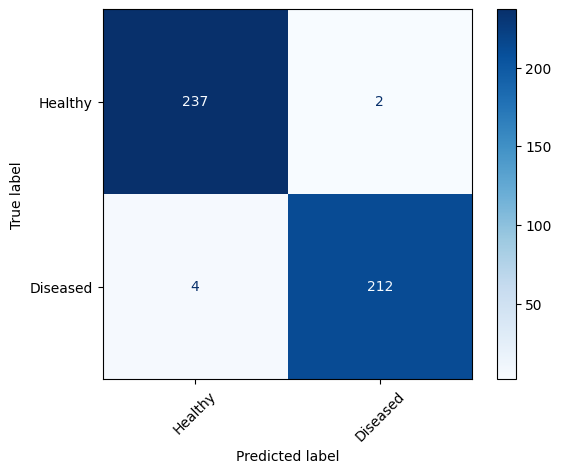

In [22]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
y_true_base = []
y_pred_base = []
y_probs_base = []

with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)
        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)
        y_true_base.extend(labels_batch.numpy())
        y_pred_base.extend(predictions.cpu().numpy())
        y_probs_base.extend(probabilities[:, 1].cpu().numpy())

print(classification_report(
    y_true_base,
    y_pred_base,
    target_names=["Healthy", "Diseased"],
    zero_division=0
))

cm_base = confusion_matrix(y_true_base, y_pred_base)

ConfusionMatrixDisplay(
    confusion_matrix=cm_base,
    display_labels=["Healthy", "Diseased"]
).plot(cmap="Blues", xticks_rotation=45)

plt.show()

In [23]:
class_counts = np.bincount(
    labels[train_idx],
    minlength=2
)

class_weights = len(train_idx) / (2 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class order: 0 = Healthy, 1 = Diseased")
print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class order: 0 = Healthy, 1 = Diseased
Class counts: [1114 1009]
Class weights: tensor([0.9529, 1.0520], device='cuda:0')


In [ ]:
# the other cnn 
weighted_model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.LazyLinear(2)
).to(device)

dummy = torch.zeros(1, 3, 128, 128).to(device)

with torch.no_grad():
    output = weighted_model(dummy)

print("Output shape:", output.shape)

weighted_loss_fn = nn.CrossEntropyLoss(
    weight=class_weights
)

weighted_optimizer = optim.Adam(
    weighted_model.parameters(),
    lr=0.001
)

best_weighted_val_acc = 0
best_weighted_weights = None

Output shape: torch.Size([1, 2])


In [25]:
for epoch in range(EPOCHS):
    weighted_model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)
        weighted_optimizer.zero_grad()
        outputs = weighted_model(images)
        loss = weighted_loss_fn(outputs, labels_batch)
        loss.backward()
        weighted_optimizer.step()
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels_batch).sum().item()
        total += labels_batch.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    weighted_model.eval()

    val_correct = 0
    val_total = 0
    val_loss_total = 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)
            outputs = weighted_model(images)
            loss = weighted_loss_fn(outputs, labels_batch)
            val_loss_total += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    if val_acc > best_weighted_val_acc:

        best_weighted_val_acc = val_acc

        best_weighted_weights = {
            key: value.detach().cpu().clone()
            for key, value in weighted_model.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc*100:.2f}%"
    )

weighted_model.load_state_dict(best_weighted_weights)

print("\nBest validation accuracy:", best_weighted_val_acc * 100)

Epoch [1/10] Train Loss: 0.4485 Train Acc: 81.11% Val Loss: 0.1497 Val Acc: 94.07%
Epoch [2/10] Train Loss: 0.0983 Train Acc: 96.70% Val Loss: 0.0590 Val Acc: 98.46%
Epoch [3/10] Train Loss: 0.0721 Train Acc: 97.83% Val Loss: 0.0679 Val Acc: 97.58%
Epoch [4/10] Train Loss: 0.0475 Train Acc: 98.26% Val Loss: 0.0461 Val Acc: 98.24%
Epoch [5/10] Train Loss: 0.0282 Train Acc: 99.25% Val Loss: 0.0530 Val Acc: 98.68%
Epoch [6/10] Train Loss: 0.0214 Train Acc: 99.25% Val Loss: 0.0420 Val Acc: 98.46%
Epoch [7/10] Train Loss: 0.0144 Train Acc: 99.67% Val Loss: 0.0353 Val Acc: 98.46%
Epoch [8/10] Train Loss: 0.0061 Train Acc: 99.95% Val Loss: 0.0405 Val Acc: 98.46%
Epoch [9/10] Train Loss: 0.0038 Train Acc: 99.95% Val Loss: 0.0552 Val Acc: 97.58%
Epoch [10/10] Train Loss: 0.0037 Train Acc: 100.00% Val Loss: 0.0335 Val Acc: 98.90%

Best validation accuracy: 98.9010989010989


              precision    recall  f1-score   support

     Healthy       0.98      0.99      0.99       239
    Diseased       0.99      0.98      0.98       216

    accuracy                           0.98       455
   macro avg       0.98      0.98      0.98       455
weighted avg       0.98      0.98      0.98       455



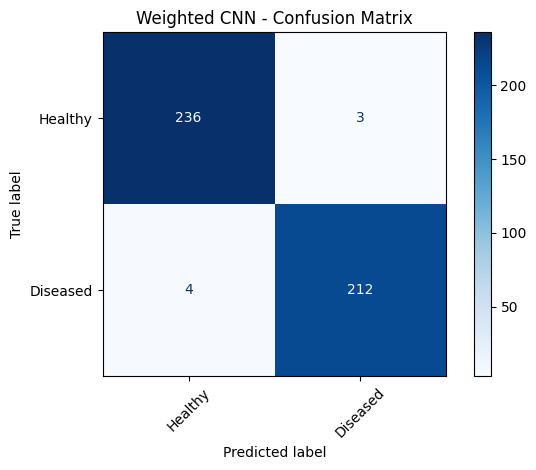

In [26]:
weighted_model.eval()

y_true_weighted = []
y_pred_weighted = []
y_probs_weighted = []

with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)
        outputs = weighted_model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)
        y_true_weighted.extend(labels_batch.numpy())
        y_pred_weighted.extend(predictions.cpu().numpy())
        y_probs_weighted.extend(probabilities[:, 1].cpu().numpy())

print(classification_report(
    y_true_weighted,
    y_pred_weighted,
    target_names=["Healthy", "Diseased"],
    zero_division=0
))

cm_weighted = confusion_matrix(
    y_true_weighted,
    y_pred_weighted
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_weighted,
    display_labels=["Healthy", "Diseased"]
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Weighted CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

baseline_results = {
    "Accuracy": accuracy_score(y_true_base, y_pred_base),
    "Diseased Precision": precision_score(y_true_base, y_pred_base, zero_division=0),
    "Diseased Recall": recall_score(y_true_base, y_pred_base, zero_division=0),
    "Diseased F1": f1_score(y_true_base, y_pred_base, zero_division=0)
}

weighted_results = {
    "Accuracy": accuracy_score(y_true_weighted, y_pred_weighted),
    "Diseased Precision": precision_score(y_true_weighted, y_pred_weighted, zero_division=0),
    "Diseased Recall": recall_score(y_true_weighted, y_pred_weighted, zero_division=0),
    "Diseased F1": f1_score(y_true_weighted, y_pred_weighted, zero_division=0)
}

comparison = pd.DataFrame(
    [baseline_results, weighted_results],
    index=["Baseline", "Weighted"]
)

display(comparison.round(4))

,Accuracy,Diseased Precision,Diseased Recall,Diseased F1
Baseline,0.9868,0.9907,0.9815,0.9860
Weighted,0.9846,0.9860,0.9815,0.9838


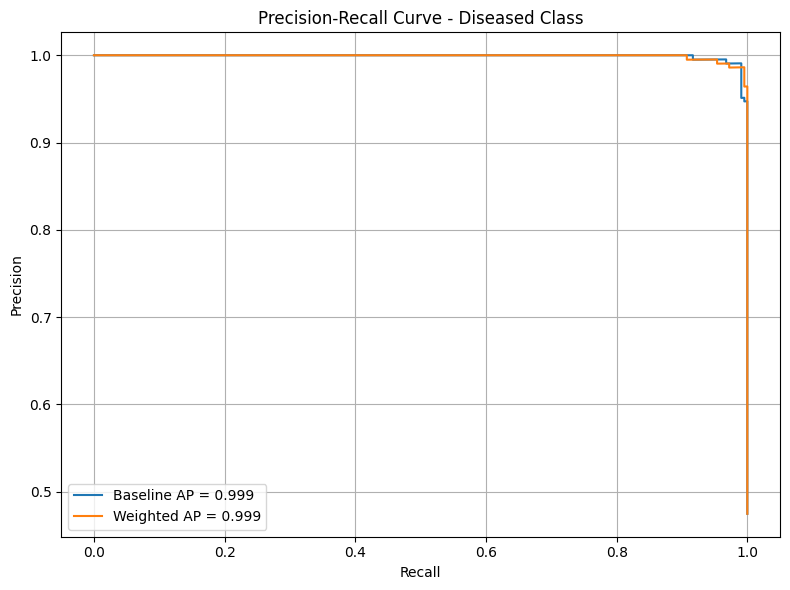

Baseline Average Precision: 0.9991
Weighted Average Precision: 0.9991


In [28]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_base, recall_base, _ = precision_recall_curve(
    y_true_base,
    y_probs_base
)

precision_weighted, recall_weighted, _ = precision_recall_curve(
    y_true_weighted,
    y_probs_weighted
)

ap_base = average_precision_score(
    y_true_base,
    y_probs_base
)

ap_weighted = average_precision_score(
    y_true_weighted,
    y_probs_weighted
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_base,
    precision_base,
    label=f"Baseline AP = {ap_base:.3f}"
)

plt.plot(
    recall_weighted,
    precision_weighted,
    label=f"Weighted AP = {ap_weighted:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Diseased Class")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

print("Baseline Average Precision:", round(ap_base, 4))
print("Weighted Average Precision:", round(ap_weighted, 4))